# Fig. 6g: biophysical ground truth neuron type distribution (evoked model)

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel g of the paper: the number and the proportion of the model neurons of each type in the evoked biophysical ground truth. A neuron type is the combination of its synapse class (excitatory EXC or inhibitory INH), its layer (layers 2 and 3 are merged) and its electrical type (etype). Source data and svg are saved in figures/8_source_data/fig6g/.

**method (as in the paper's notebook fig6_G_H_selection_bias.ipynb)**
* ground truth: all 1,836 neurons of the evoked simulation (the neurons do not depend on the duration of the simulation)
* the types are sorted by synapse class and layer; the proportion of a type is its count divided by the number of neurons
* the figure shows the proportion of each type (blue line) and the number of neurons of the type (numbers)

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
import spikeinterface as si
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
from src.nodes.analysis.features import features as feat

# paths
GT_PATH = "dataset/00_raw/ground_truth_npx_evoked"

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Load the ground truth and count the neuron types

In [2]:
%%time

SortingTrue = si.load_extractor(GT_PATH)

# synapse class, layer and etype of each ground truth neuron
df_gt = feat.get_unit_features(SortingTrue)[["synapse", "layer", "etype"]]

# unique types, sorted by synapse class and layer
unique_type = df_gt.drop_duplicates().sort_values(by=["synapse", "layer"])

# number of neurons of each type
count_gt = feat.count_unit_type(df_gt, unique_type)
print("neurons:", len(df_gt), "| types:", len(count_gt))

neurons: 1836 | types: 35
CPU times: user 3.36 s, sys: 1.12 ms, total: 3.37 s
Wall time: 3.37 s


## Source data: count and proportion of each neuron type

In [3]:
df = pd.DataFrame({"synapse_class": [t[0] for t in count_gt["type"]], "layer": [t[1] for t in count_gt["type"]], "etype": [t[2] for t in count_gt["type"]],
                   "count": count_gt["count"].values})
df["probability"] = df["count"] / df["count"].sum()
df["n_neurons"] = df["count"].sum()
display(df.round(4))

,synapse_class,layer,etype,count,probability,n_neurons
0,EXC,L2/3,cADpyr,342,0.1863,1836
1,EXC,L4,cADpyr,286,0.1558,1836
2,EXC,L5,cADpyr,389,0.2119,1836
3,EXC,L6,cADpyr,658,0.3584,1836
4,INH,L1,cACint,2,0.0011,1836
5,INH,L1,cNAC,4,0.0022,1836
6,INH,L2/3,dNAC,4,0.0022,1836
7,INH,L2/3,cNAC,6,0.0033,1836
8,INH,L2/3,bAC,3,0.0016,1836
9,INH,L2/3,cACint,11,0.0060,1836


In [4]:
def plot_source_data(df: pd.DataFrame):
    """Proportion of the ground truth neurons of each type (blue line) and number of neurons of the type (numbers). Types are sorted by
    synapse class (EXC, INH) and layer"""

    fig, ax = plt.subplots(1, 1, figsize=(0.9, 5.7))
    yticks = np.arange(0, len(df), 1)
    ax.plot(df["probability"].values, yticks, label="ground truth")
    for ix in range(len(df)):
        ax.text(x=df["probability"].iloc[ix] + 0.01, y=yticks[ix], s=str(df["count"].iloc[ix]))

    # aesthetics
    labels = [f"'{layer}', {etype}" for layer, etype in zip(df["layer"], df["etype"])]
    ax.set_xlim(left=-1e-2)
    ax.set_ylim([0, len(df) - 1])
    ax.set_yticks(yticks, labels, rotation=0, fontsize=5.4)
    ax.set_xlabel("Probability \n(ratio)")
    ax.invert_yaxis()
    ax.spines[["right", "top"]].set_visible(False)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.spines["left"].set_position(("axes", -0.05))

    # synapse class of the rows
    for synapse in ["EXC", "INH"]:
        rows = np.where(df["synapse_class"].values == synapse)[0]
        ax.text(-1.75, rows.mean(), synapse, transform=ax.get_yaxis_transform(), ha="center", va="center", fontsize=8)
        ax.plot([-1.2, -1.2], [rows.min() - 0.4, rows.max() + 0.4], color="k", linewidth=0.8, transform=ax.get_yaxis_transform(), clip_on=False)      # vertical bar of the group
    ax.text(-1.5, -0.9, "Model neuron type", transform=ax.get_yaxis_transform(), ha="center", va="bottom")
    ax.text(0.5, 1.055, "Biophysical ground truth\nneuron type distribution", transform=ax.transAxes, ha="center", va="bottom", fontweight="bold", fontsize=6.5)
    ax.text(0.5, 1.032, "(evoked model)", transform=ax.transAxes, ha="center", va="bottom", fontsize=6)
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 198 ms, sys: 7 ms, total: 205 ms
Wall time: 205 ms


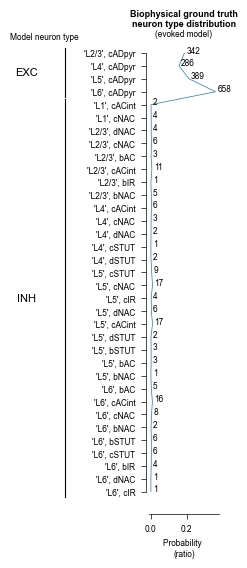

In [5]:
%%time

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/fig6g", exist_ok=True)
plt.savefig("figures/8_source_data/fig6g/fig6g.svg", bbox_inches="tight", **savefig_cfg)

# save source data
df.to_excel("figures/8_source_data/fig6g/fig6g.xlsx", index=False)

## Check: replot from the saved source data

CPU times: user 25.8 ms, sys: 0 ns, total: 25.8 ms
Wall time: 25.8 ms


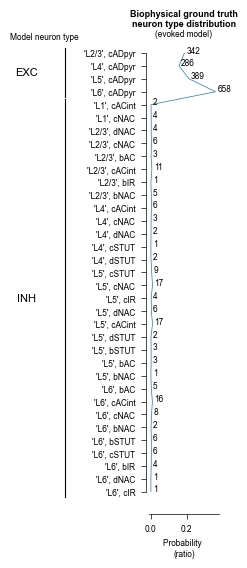

In [6]:
%%time

df = pd.read_excel("figures/8_source_data/fig6g/fig6g.xlsx")
fig, ax = plot_source_data(df)